# Milestone 2 — fine-tuning a separator on Sanidha

Trains the demixing network from `configs/default.yaml`, then charts what happened:
loss curves, per-stem validation SDR against the Milestone 1 HPSS baseline, and a
per-track evaluation of the selected checkpoint.

* **Run it top to bottom** to train. On a GPU, HTDemucs takes hours; every epoch is
  checkpointed, so an interrupted run resumes (set `RESUME = True`).
* **Set `RUN_TRAINING = False`** to only re-draw the charts from a finished run's
  `history.json` — no GPU needed.

Settings come from the config file; nothing below hard-codes a hyperparameter.

In [1]:
import copy
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Run from the repository root whether Jupyter was started there or in notebooks/.
if not Path("configs").is_dir() and Path("../configs").is_dir():
    os.chdir("..")

from indian_mss.config import load_config

cfg = load_config("configs/default.yaml")


def deep_merge(base, extra):
    out = copy.deepcopy(base)
    for k, v in extra.items():
        out[k] = deep_merge(out[k], v) if isinstance(v, dict) and isinstance(out.get(k), dict) else v
    return out


# Environment overrides exist for smoke-testing the notebook on synthetic data;
# for a real run, edit configs/default.yaml instead.
cfg = deep_merge(cfg, json.loads(os.environ.get("IMSS_CONFIG_OVERRIDES", "{}")))

SANIDHA_ROOT = os.environ.get("IMSS_SANIDHA_ROOT", cfg["data"]["sanidha_root"])
RUN_DIR = Path(os.environ.get("IMSS_RUN_DIR", f"checkpoints/{cfg['train']['backbone']}"))
RUN_TRAINING = os.environ.get("IMSS_RUN_TRAINING", "1") == "1"
RESUME = False
PRETRAINED = os.environ.get("IMSS_PRETRAINED", "1") == "1"

print(f"backbone {cfg['train']['backbone']}, data {SANIDHA_ROOT}, run dir {RUN_DIR}")

backbone htdemucs, data data/sanidha_flat, run dir checkpoints/htdemucs_concertsplit


## 1. Dataset

In [2]:
from indian_mss.data.sanidha import Sanidha
from indian_mss.train.report import dataset_stats

corpus = Sanidha(SANIDHA_ROOT, cfg["stft"]["sample_rate"], stems=tuple(cfg["data"]["stems"]))
stats = dataset_stats(corpus)
print(f"{stats['tracks']} tracks, {stats['hours']:.2f} h")
for stem, hours in stats["stem_hours"].items():
    print(f"  {stem:10s} {hours:6.2f} h")

37 tracks, 7.90 h
  ghatam       2.31 h
  mridangam    7.90 h
  violin       7.90 h
  vocal        7.90 h


## 2. Baseline to beat

The Milestone 1 HPSS numbers, from `python scripts/preprocess.py --evaluate`.
HPSS only splits melodic from percussive, so it is a floor, not a like-for-like
comparison with four instrument stems.

In [3]:
from indian_mss.train.report import load_baseline

baseline = load_baseline("out/hpss_baseline.json")
if baseline is None:
    print("no out/hpss_baseline.json yet -- run: python scripts/preprocess.py --evaluate")
else:
    for name, m in baseline.items():
        print(f"HPSS {name:10s} SDR {m['sdr']:+.2f} dB  SIR {m['sir']:+.2f} dB  SAR {m['sar']:+.2f} dB")

HPSS harmonic   SDR +6.84 dB  SIR +10.26 dB  SAR +10.51 dB
HPSS percussive SDR -1.28 dB  SIR +8.67 dB  SAR +0.87 dB


## 3. Train

Phase 1 trains only the re-targeted output head with the pretrained network frozen;
phase 2 unfreezes the blocks listed in `train.unfreeze` at the 10× lower
`encoder_lr`. `best.pt` is chosen by mean validation SDR.

In [4]:
if RUN_TRAINING:
    from indian_mss.train.loop import train

    history = train(cfg, SANIDHA_ROOT, RUN_DIR, pretrained=PRETRAINED, resume=RESUME, progress=True)
else:
    history = json.loads((RUN_DIR / "history.json").read_text())
print(f"{len(history['epochs'])} epochs, {len(history['steps'])} steps")

56 epochs, 56000 steps


## 4. Loss curves

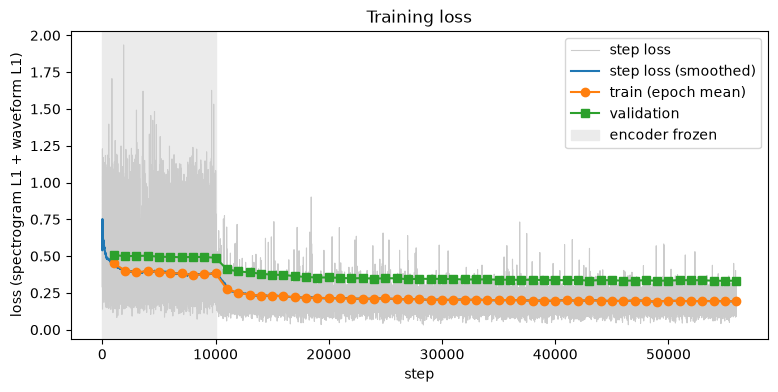

In [5]:
from indian_mss.train.report import plot_losses

plot_losses(history)
plt.show()

## 5. Validation SDR per stem

Per stem, because a mean can hide a model that nails the vocal and fails the ghatam.

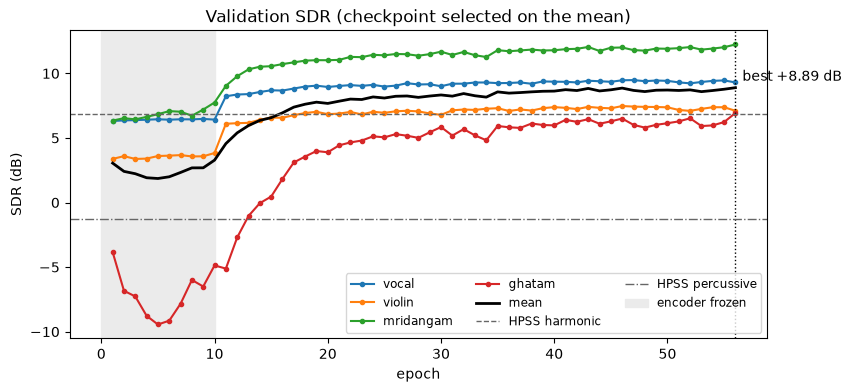

In [6]:
from indian_mss.train.report import plot_val_sdr

plot_val_sdr(history, baseline)
plt.show()

## 6. Selected checkpoint on the held-out tracks

SDR, SIR and SAR per track and stem. SIR is the bleed number: how much of the
*other* instruments is left in each stem.

In [7]:
from indian_mss.eval.sdr import evaluate_stems
from indian_mss.models.separator import load_separator, separate
from indian_mss.train.loop import _load_val_items

model, meta = load_separator(RUN_DIR / "best.pt")
print(f"best.pt: epoch {meta['epoch']}, backbone {meta['backbone']}")
items = _load_val_items(corpus, meta["val_tracks"], cfg["train"].get("val_seconds", 60.0), meta["sources"])

print(f"{'track':16s} {'stem':10s} {'SDR':>7s} {'SIR':>7s} {'SAR':>7s}")
for item in items:
    est = separate(model, item["mixture"], meta["stft_config"].sample_rate, meta["segment_seconds"])
    refs = {s: item["stems"][s] for s in meta["sources"] if s in item["stems"] and np.any(item["stems"][s])}
    scores = evaluate_stems({s: est[i] for i, s in enumerate(meta["sources"]) if s in refs}, refs)
    for stem, m in scores.items():
        print(f"{item['track_id']:16s} {stem:10s} {m['sdr']:+7.2f} {m['sir']:+7.2f} {m['sar']:+7.2f}")

best.pt: epoch 56, backbone htdemucs


/home/tejas-agarwal/Programming/AI/Indian_Musicology_Gradient/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


track            stem           SDR     SIR     SAR


Concert03_01-Vanajakshi-Varnam vocal        +8.67  +15.90   +9.69
Concert03_01-Vanajakshi-Varnam violin       +6.13  +17.64   +6.53
Concert03_01-Vanajakshi-Varnam mridangam   +11.51  +24.41  +11.76
Concert03_01-Vanajakshi-Varnam ghatam       +7.50  +28.64   +7.54


Concert03_02-Sharanam-Bhavan vocal        +7.38  +14.17   +8.57
Concert03_02-Sharanam-Bhavan violin       +5.46  +18.63   +5.74
Concert03_02-Sharanam-Bhavan mridangam   +12.51  +25.48  +12.75
Concert03_02-Sharanam-Bhavan ghatam       +4.83  +22.81   +4.92


Concert03_03-Shambo-Sathatham vocal       +11.73  +21.93  +12.20
Concert03_03-Shambo-Sathatham violin       +8.79  +23.73   +8.95
Concert03_03-Shambo-Sathatham mridangam   +12.24  +24.66  +12.51
Concert03_03-Shambo-Sathatham ghatam       +4.11  +30.89   +4.13


Concert03_04-Baaraiya-Ranga vocal        +9.34  +17.03  +10.24
Concert03_04-Baaraiya-Ranga violin       +6.59  +19.14   +6.89
Concert03_04-Baaraiya-Ranga mridangam   +12.46  +28.12  +12.58
Concert03_04-Baaraiya-Ranga ghatam       +6.63  +27.61   +6.68


Concert03_05-Ramanatham-Bhajeham vocal       +10.13  +19.99  +10.64
Concert03_05-Ramanatham-Bhajeham violin       +9.24  +19.37   +9.73
Concert03_05-Ramanatham-Bhajeham mridangam   +14.87  +34.79  +14.92
Concert03_05-Ramanatham-Bhajeham ghatam      +11.41  +33.96  +11.44


Concert03_06-Venkatachala-Nilayam vocal        +8.54  +15.91   +9.53
Concert03_06-Venkatachala-Nilayam violin       +6.41  +18.01   +6.79
Concert03_06-Venkatachala-Nilayam mridangam    +9.83  +24.10  +10.01
Concert03_06-Venkatachala-Nilayam ghatam       +6.81  +25.84   +6.88


## 7. Live test: Saraga

The selected checkpoint on all 168 Saraga Carnatic multitracks: live concerts whose
close mics carry real bleed, never seen in training. Scores come from
`python scripts/evaluate.py` (central 60 s of each track, mixture = sum of the close
mics); this cell only reads them. Medians sit beside means because in pieces where an
instrument is silent its mic holds only bleed, and scoring that as the reference
drags the mean down (see `deliverables/milestone_2_model/README.md`).

Saraga, 168 tracks (checkpoint epoch 56)
  vocal      mean  +4.21  median  +5.89 dB   (168 tracks)   Concert03  +9.30
  violin     mean  +1.27  median  +0.88 dB   (168 tracks)   Concert03  +7.11
  mridangam  mean  +4.83  median  +8.68 dB   (168 tracks)   Concert03 +12.24
  ghatam     mean  -8.47  median  -5.95 dB   (46 tracks)   Concert03  +6.93
  3-stem mean +3.44 dB (168 tracks), 4-stem mean -0.62 dB (46 tracks)


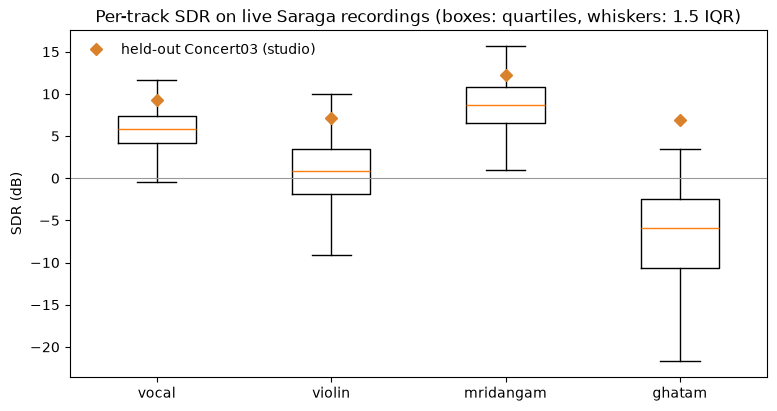

In [8]:
saraga = json.loads(Path("deliverables/milestone_2_model/saraga/saraga_eval.json").read_text())
rows = saraga["per_track"]
stems = list(meta["sources"])
per_stem = {s: [r["scores"]["stems"][s]["sdr"] for r in rows if s in r["scores"].get("stems", {})] for s in stems}
val = next(e["val_sdr"] for e in history["epochs"] if e["epoch"] == meta["epoch"])

summary = saraga["summary"]["stems"]
print(f"Saraga, {len(rows)} tracks (checkpoint epoch {saraga['checkpoint_epoch']})")
for s in stems:
    v = np.array(per_stem[s])
    print(f"  {s:10s} mean {v.mean():+6.2f}  median {np.median(v):+6.2f} dB   ({len(v)} tracks)   Concert03 {val[s]:+6.2f}")
print(f"  3-stem mean {summary['mean_3stem']['sdr']:+.2f} dB ({summary['mean_3stem']['n_tracks']} tracks), "
      f"4-stem mean {summary['mean_4stem']['sdr']:+.2f} dB ({summary['mean_4stem']['n_tracks']} tracks)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([per_stem[s] for s in stems], tick_labels=stems, showfliers=False)
ax.plot(range(1, len(stems) + 1), [val[s] for s in stems], "D", color="#D9822B", label="held-out Concert03 (studio)")
ax.axhline(0, color="#999", lw=0.8)
ax.set_ylabel("SDR (dB)")
ax.set_title("Per-track SDR on live Saraga recordings (boxes: quartiles, whiskers: 1.5 IQR)")
ax.legend(frameon=False)
plt.show()

## Next

* **Milestone 3**: `scripts/compare_resynthesis.py` turns these masks into stems and
  compares mixture-phase ISTFT, Griffin-Lim and a BigVGAN vocoder
  (`deliverables/milestone_3_resynthesis/`).
* **Milestone 4**: the timbre classifier measures how much bleed the separated stems
  keep, on Concert03 and on live Saraga (`deliverables/milestone_4_classifier/`).